*openmobisim tutorials* · [00 · overview](00_getting_started.ipynb) · ← [04 · Bikes, walking, transit and the choice of mode](04_multimodal.ipynb) · [06 · Parameters and experiments](06_parameters_and_experiments.ipynb) → · [documentation](https://openmobisim.github.io)

# 05 · Results and figures

Everything a run leaves behind: the answers on the `Run` object, the files in its folder (Parquet and JSON, readable by
any tool), and the figures `openmobisim.viz` draws from them. One run on a grid serves the whole notebook.

**Download** {download}`this notebook <../_static/notebooks/05_results_and_figures.ipynb>` or {download}`all ten <../_static/notebooks/openmobisim_notebooks.zip>` (a zip), without their outputs. The Installation section below installs openmobisim; its last command, `openmobisim notebooks`, copies the same ten into a folder and opens the first in JupyterLab.

---

## Installation

> Skip this if `import openmobisim` already works in this notebook. **One install is all there is:**
> `pip install "openmobisim[all]"` brings the simulator and everything the ten tutorials use (JupyterLab,
> matplotlib for the figures, pandas, polars and pyarrow for the tables); nothing is installed later. Find the case
> that matches yours and copy its commands, in order. Each needs Python 3.11 or newer.
>
> **A new conda environment** (any system; openmobisim is on PyPI, so pip installs it into the environment):
>
> ```bash
> conda create -y -n openmobisim python=3.12
> conda activate openmobisim
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on macOS or Linux** (in a terminal):
>
> ```bash
> python3 -m venv openmobisim
> source openmobisim/bin/activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on Windows** (in the Command Prompt):
>
> ```bat
> py -m venv openmobisim
> openmobisim\Scripts\activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> The last line copies these ten notebooks into `./openmobisim-notebooks` and opens them in JupyterLab. In VS Code or
> PyCharm, open a notebook and choose the `openmobisim` environment's Python as its kernel instead.
>
> **Into the environment this notebook already runs in**: paste this into a new code cell, run it, then restart the
> kernel.
>
> ```python
> %pip install "openmobisim[all]"
> ```

---

In [1]:
import json
import os

import pandas as pd
import polars as pl

import openmobisim as ms
from openmobisim import viz

net = ms.examples.manhattan_grid(n=6, block_metres=250.0, signals=True)
trips = ms.examples.trips_random(net, 20000, seed=2, spread_s=3600, min_m=500, max_m=2000)
run = ms.Scenario.from_parts(
    net, trips, classes={"commuter": (True, False, False)}, link_bin_s=900
).run("results", output_dir="runs/results")

Run 'results': 0.4 s, window 00:00–03:00, 20,000 of 20,000 trips completed, mean trip 2.6 min, verdict good (run.timings() has every stage)


## 1 · The files

| File | What is in it |
|---|---|
| `kpis.parquet` | the indicators, one row per (iteration, mode, metric) |
| `trip_results.parquet` | every trip: who, from where to where, when, by which mode, what became of it |
| `events.parquet` | a sample of what happened to the trips (completed, truncated) and when, one in a hundred |
| `link_bins.parquet` | each link's traffic and mean time in each time bin (with `link_bin_s`) |
| `diagnostics.parquet` | counters of anything unusual, one row per kind and place |
| `manifest.json` | every input, setting and default, the versions and the fingerprint |
| `timings.csv` | where the run's time went, by stage, on this machine's clock |

Each is a plain file: read it with pandas, polars, pyarrow, R or a spreadsheet, without openmobisim.

In [2]:
folder = "runs/results"
for name in sorted(os.listdir(folder)):
    print(f"{name:22s} {os.path.getsize(os.path.join(folder, name)):>9,d} bytes")

diagnostics.parquet          894 bytes
events.parquet             3,591 bytes
kpis.parquet               3,193 bytes
link_bins.parquet         13,692 bytes
manifest.json              1,765 bytes
timings.csv                  954 bytes
trip_results.parquet     387,955 bytes


## 2 · Indicators

`kpis.parquet` is in long format. The last iteration's run-wide indicators:

In [3]:
kpis = pl.read_parquet(f"{folder}/kpis.parquet")
last = kpis.filter((pl.col("iteration") == kpis["iteration"].max()) & (pl.col("mode") == "all"))
last.select("metric", "value")

metric,value
str,f64
"""total_travel_time_s""",3.081894e6
"""completed_trips""",20000.0
"""truncated_trips""",0.0
"""completed_people""",20000.0
"""reselected_share""",0.1635
…,…
"""people""",20000.0
"""no_vehicle_available_trips""",0.0
"""no_feasible_path_trips""",0.0


The same table through the `Run` (`run.kpis().to_pandas()` or `.to_polars()`), pivoted to one row per iteration:

In [4]:
k = run.kpis().to_pandas()
k[k["mode"] == "all"].pivot(index="iteration", columns="metric", values="value")[
    ["completed_trips", "total_travel_time_s", "gap", "gap_excess", "changed_share"]
].round(4)

metric,completed_trips,total_travel_time_s,gap,gap_excess,changed_share
iteration,,,,,
0,20000.0,8069276.0,1.4837,1.4628,NaN
1,20000.0,9738350.0,2.6961,2.6705,0.3539
2,20000.0,3442422.0,0.2455,0.1794,0.1826
3,20000.0,3182288.0,0.1126,0.0300,0.1136
4,20000.0,3094576.0,0.1044,0.0215,0.0974
5,20000.0,3081894.0,0.1013,0.0166,0.0789


## 3 · Every trip

`run.trip_results()` has one row per trip, also in the folder as `trip_results.parquet`: who travelled, from where to
where, when, by which mode, what became of the trip, and, if it completed, when it arrived and how long it took. For a
car still on the roads when the window ended, `link_at_end` is the link it was on. Filtering on `outcome` finds the
trips that did not finish.

In [5]:
t = run.trip_results().to_pandas()
print(t["outcome"].value_counts().to_string())
t[t["outcome"] != "completed"].head()

outcome
completed    20000


,trip,traveller_id,trip_seq,user_class,weight,origin_lon,origin_lat,destination_lon,destination_lat,departure_s,mode,mode_choice,outcome,arrival_s,travel_time_s,link_at_end


## 4 · Per link and per time bin

`link_bins.parquet` has one row per (bin, link) that saw traffic: `link` is the link's id (the one that survives a
rebuilt network, such as an OpenStreetMap way and direction), `link_index` its row in this network's arrays, `pcu` the
traffic that left it in the bin (in passenger car units) and `pcu_seconds` the time that traffic took. Joined with the
network's own arrays, it gives each link's flow and its delay over free flow.

In [6]:
bins = run.link_bins_table().to_pandas()
links = pd.DataFrame({
    "link_index": range(net.link_count),
    "free_flow_s": net.link_free_flow_s(),
    "capacity_pcu_h": net.link_capacity_pcu_h(),
})
bins = bins.merge(links, on="link_index")
bin_s = run.manifest()["link_bin_seconds"]
bins["flow_pcu_h"] = bins["pcu"] * 3600 / bin_s
bins["mean_s"] = bins["pcu_seconds"] / bins["pcu"]
bins["delay_ratio"] = bins["mean_s"] / bins["free_flow_s"]
columns = ["start_s", "link", "flow_pcu_h", "capacity_pcu_h", "mean_s", "free_flow_s", "delay_ratio"]
bins.sort_values("delay_ratio", ascending=False)[columns].head(8).round(2)

,start_s,link,flow_pcu_h,capacity_pcu_h,mean_s,free_flow_s,delay_ratio
591,3600,l_n_005_002__n_005_003,196.0,1800.0,49.24,18.02,2.73
412,2700,l_n_002_003__n_003_003,864.0,1800.0,86.38,38.64,2.24
559,3600,l_n_003_005__n_002_005,228.0,1800.0,39.00,18.09,2.16
366,2700,l_n_000_002__n_000_003,1556.0,1800.0,38.24,18.03,2.12
532,3600,l_n_002_003__n_003_003,172.0,1800.0,78.54,38.64,2.03
439,2700,l_n_003_005__n_002_005,1488.0,1800.0,35.94,18.09,1.99
179,900,l_n_002_005__n_003_005,1588.0,1800.0,35.36,18.09,1.95
471,2700,l_n_005_002__n_005_003,1548.0,1800.0,34.88,18.02,1.94


## 5 · The manifest and reproducibility

The manifest records what went in. Together with the package version, the **fingerprint** identifies the run: the same
fingerprint on the same version gives the same results.

In [7]:
manifest = run.manifest()
keys = ["openmobisim_version", "defaults_version", "platform", "run_fingerprint", "network_fingerprint", "flow_level",
        "route_method", "choice_descriptor", "equilibration_descriptor", "iterations_run", "converged"]
print(json.dumps({k: manifest[k] for k in keys}, indent=1))

{
 "openmobisim_version": "0.1.0",
 "defaults_version": 30,
 "platform": "aarch64-apple-darwin",
 "run_fingerprint": "eb7d434537f8470c",
 "network_fingerprint": "dfa893b06adf093b",
 "flow_level": 2,
 "route_method": "shortest",
 "choice_descriptor": "logit;beta_bike_mixed_km=-0.16;beta_cost_eur=-1.2;beta_ln_path_size=1;beta_time_min=-0.2;beta_transfers=-1;beta_wait_min=-0.09;beta_walk_min=-0.13",
 "equilibration_descriptor": "msa;cost_bin_s=300;gap_sample=300;gap_tolerance=0.05;increments=5;itinerary_gap_sample=100000000;iterations=10;route_growth_tolerance=1;warmup=1",
 "iterations_run": 6,
 "converged": true
}


## 6 · Where the time went

Every run says in one line how long it took (unless `quiet=True`; the logger `openmobisim` at `DEBUG` adds the table)
and keeps its wall-clock time by stage in `Run.timings()` and `timings.csv`.

In [8]:
t = run.timings().to_pandas()
t[t["iteration"].isna()][["stage", "seconds"]].round(3)

,stage,seconds
0,demand_read,0.009
1,setup,0.002
2,static_routes,0.006
3,itineraries_setup,0.000
4,route_sets,0.000
37,results_assembled,0.000
38,results_written,0.011
39,total,0.377


## 7 · Figures

The figures share one look: a flow map (`map_link`), the demand (`map_demand`, `chart_demand_matrix`), a pair's route set
(`map_route`), mode shares (`chart_mode_share`, notebook 04), transit and parkings (`map_transit`, `map_parking`), an
interactive page (`map_interactive`) and a one-page summary of a run (`summary`). Each takes `theme="paper"` (the
default) or `"night"`, a size in centimetres (`size_cm`) and a `path` to save to (PNG, PDF or SVG by the extension).

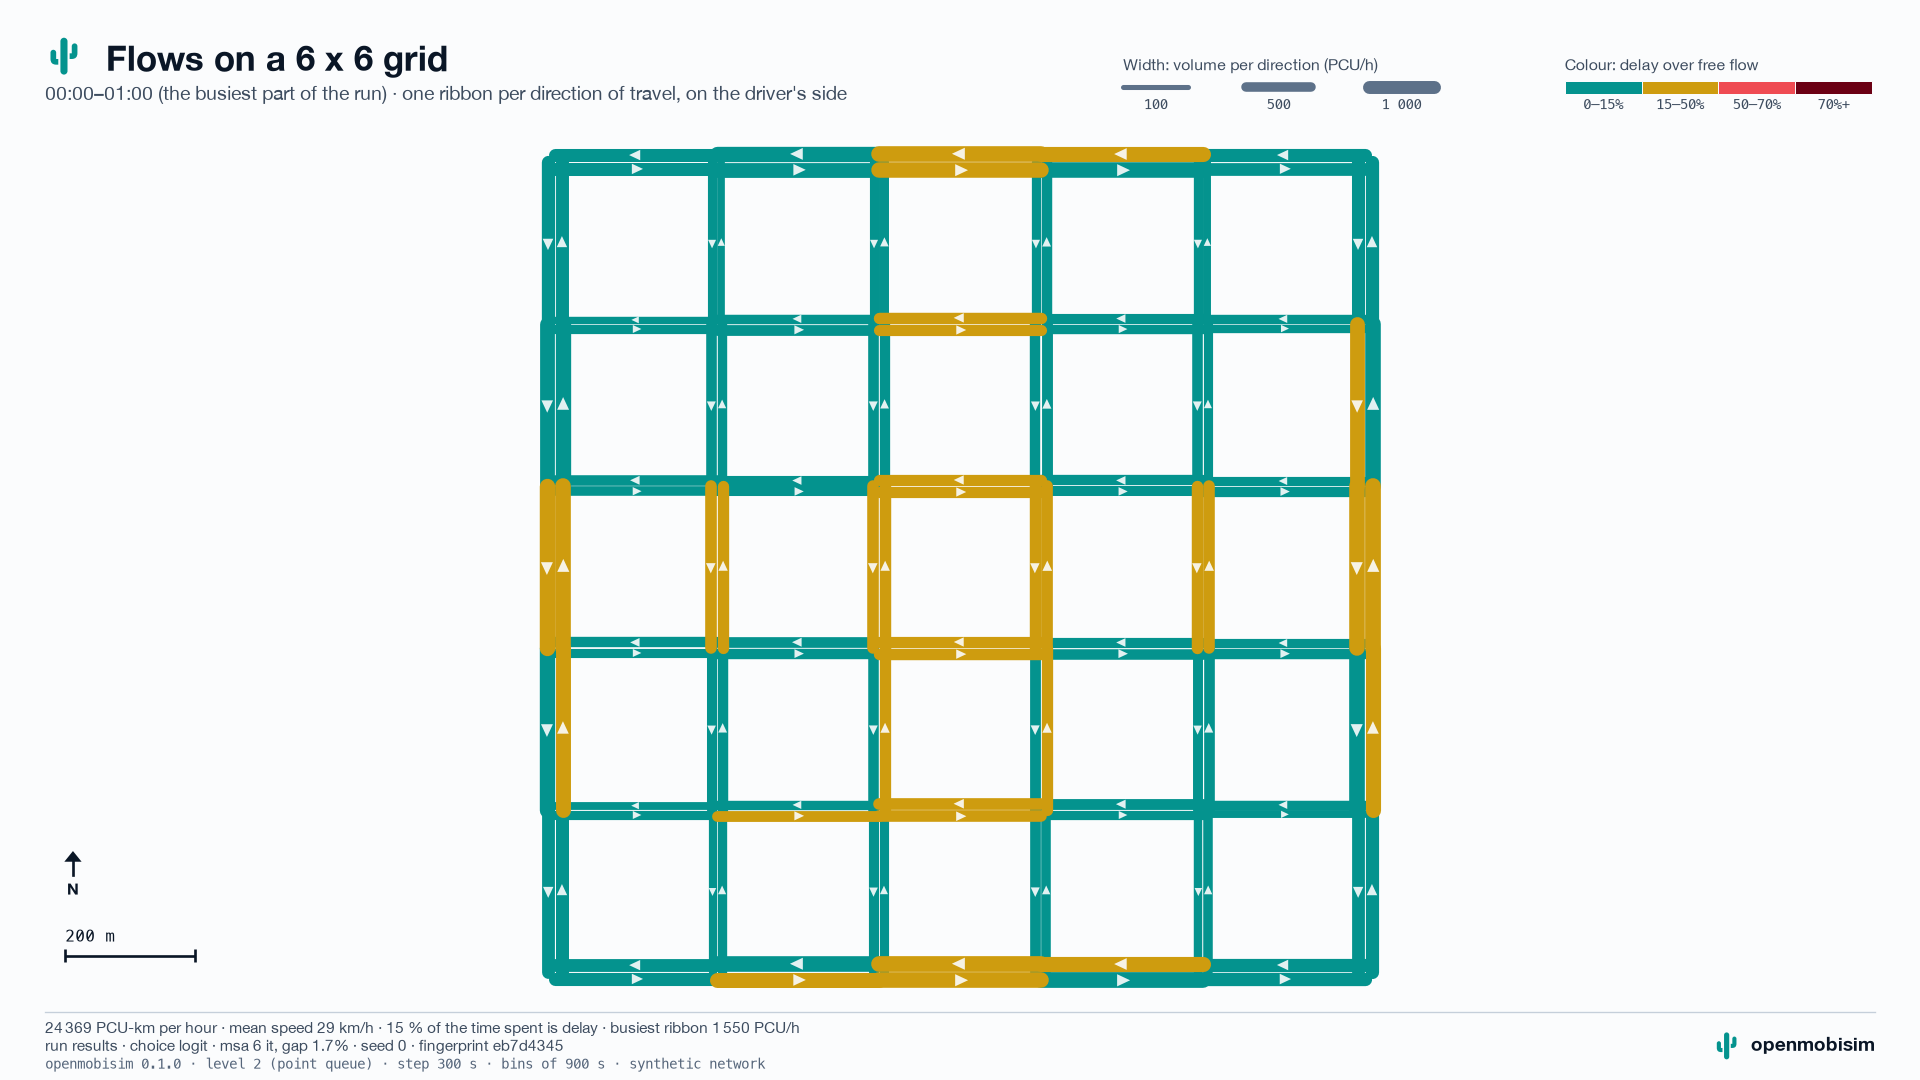

In [9]:
viz.map_link(run, title="Flows on a 6 x 6 grid")

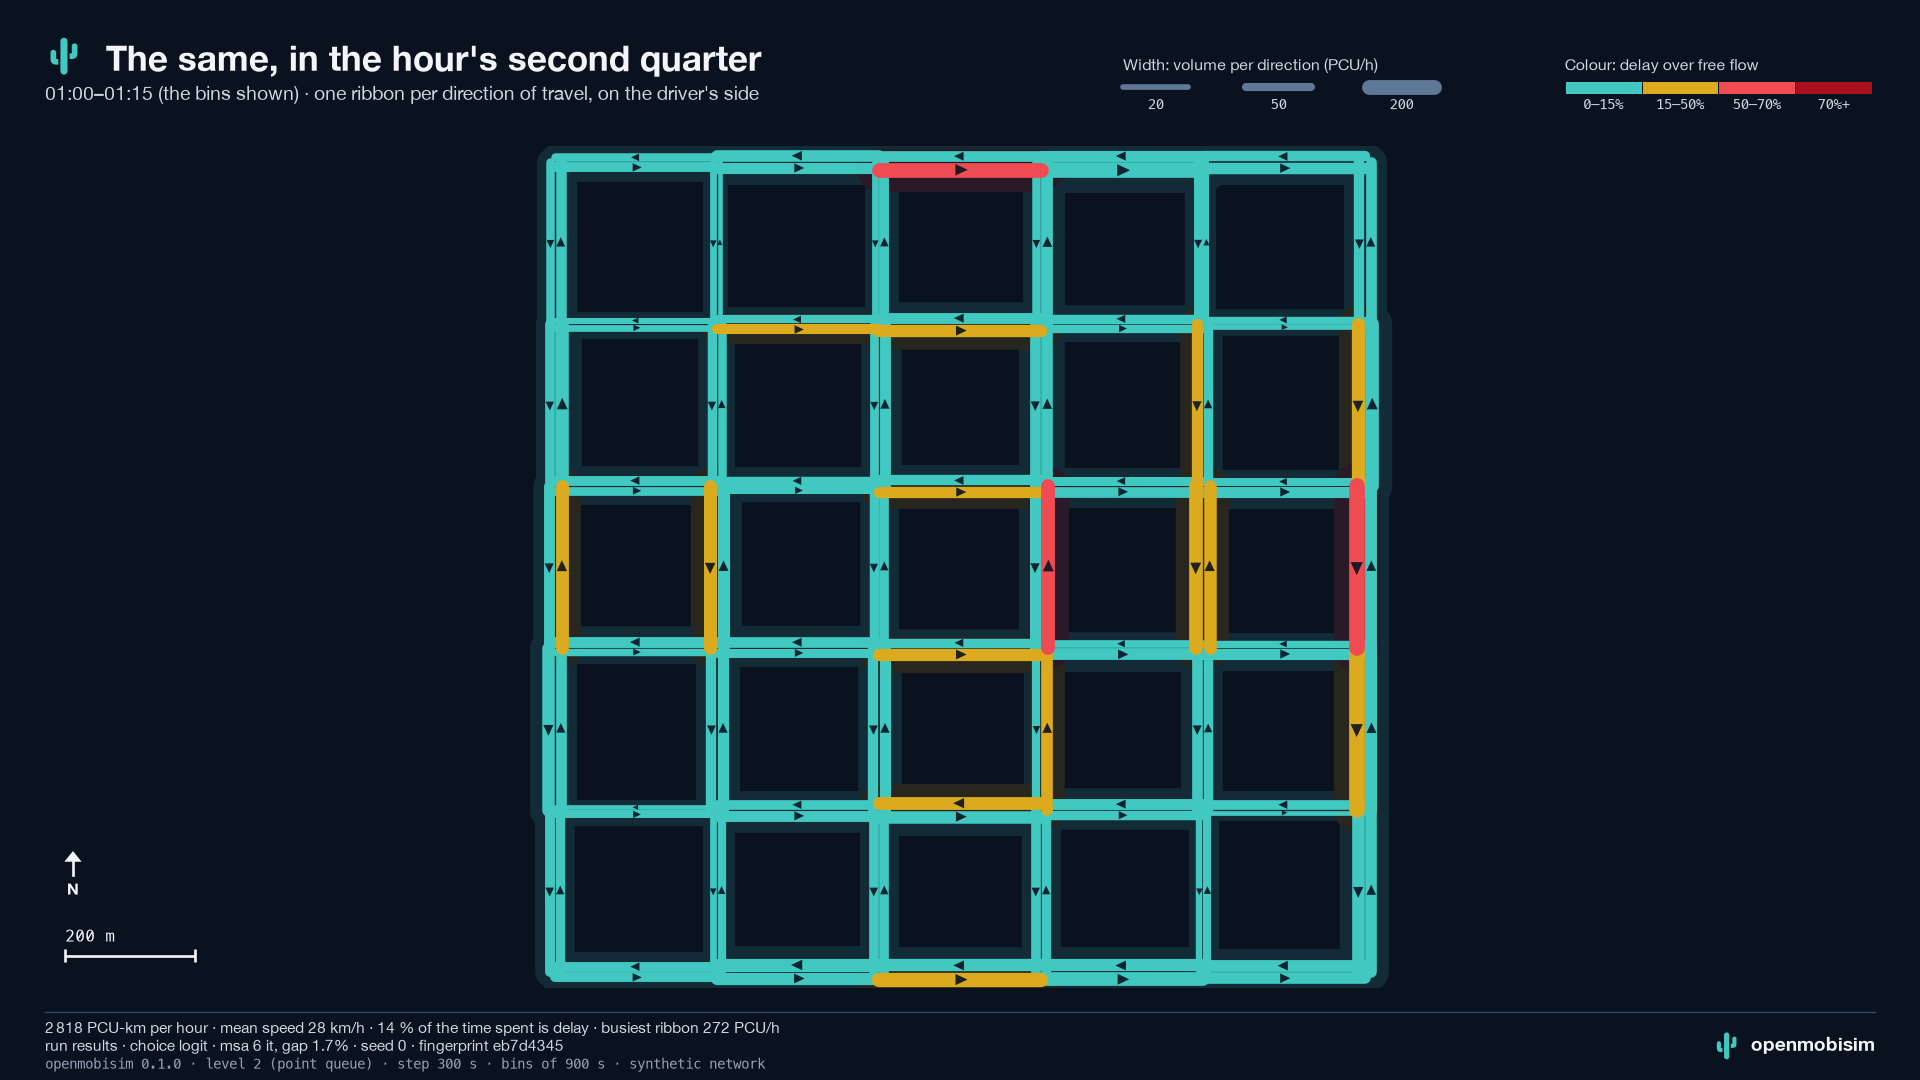

In [10]:
viz.map_link(run, theme="night", bins=4, title="The same, in the hour's second quarter")

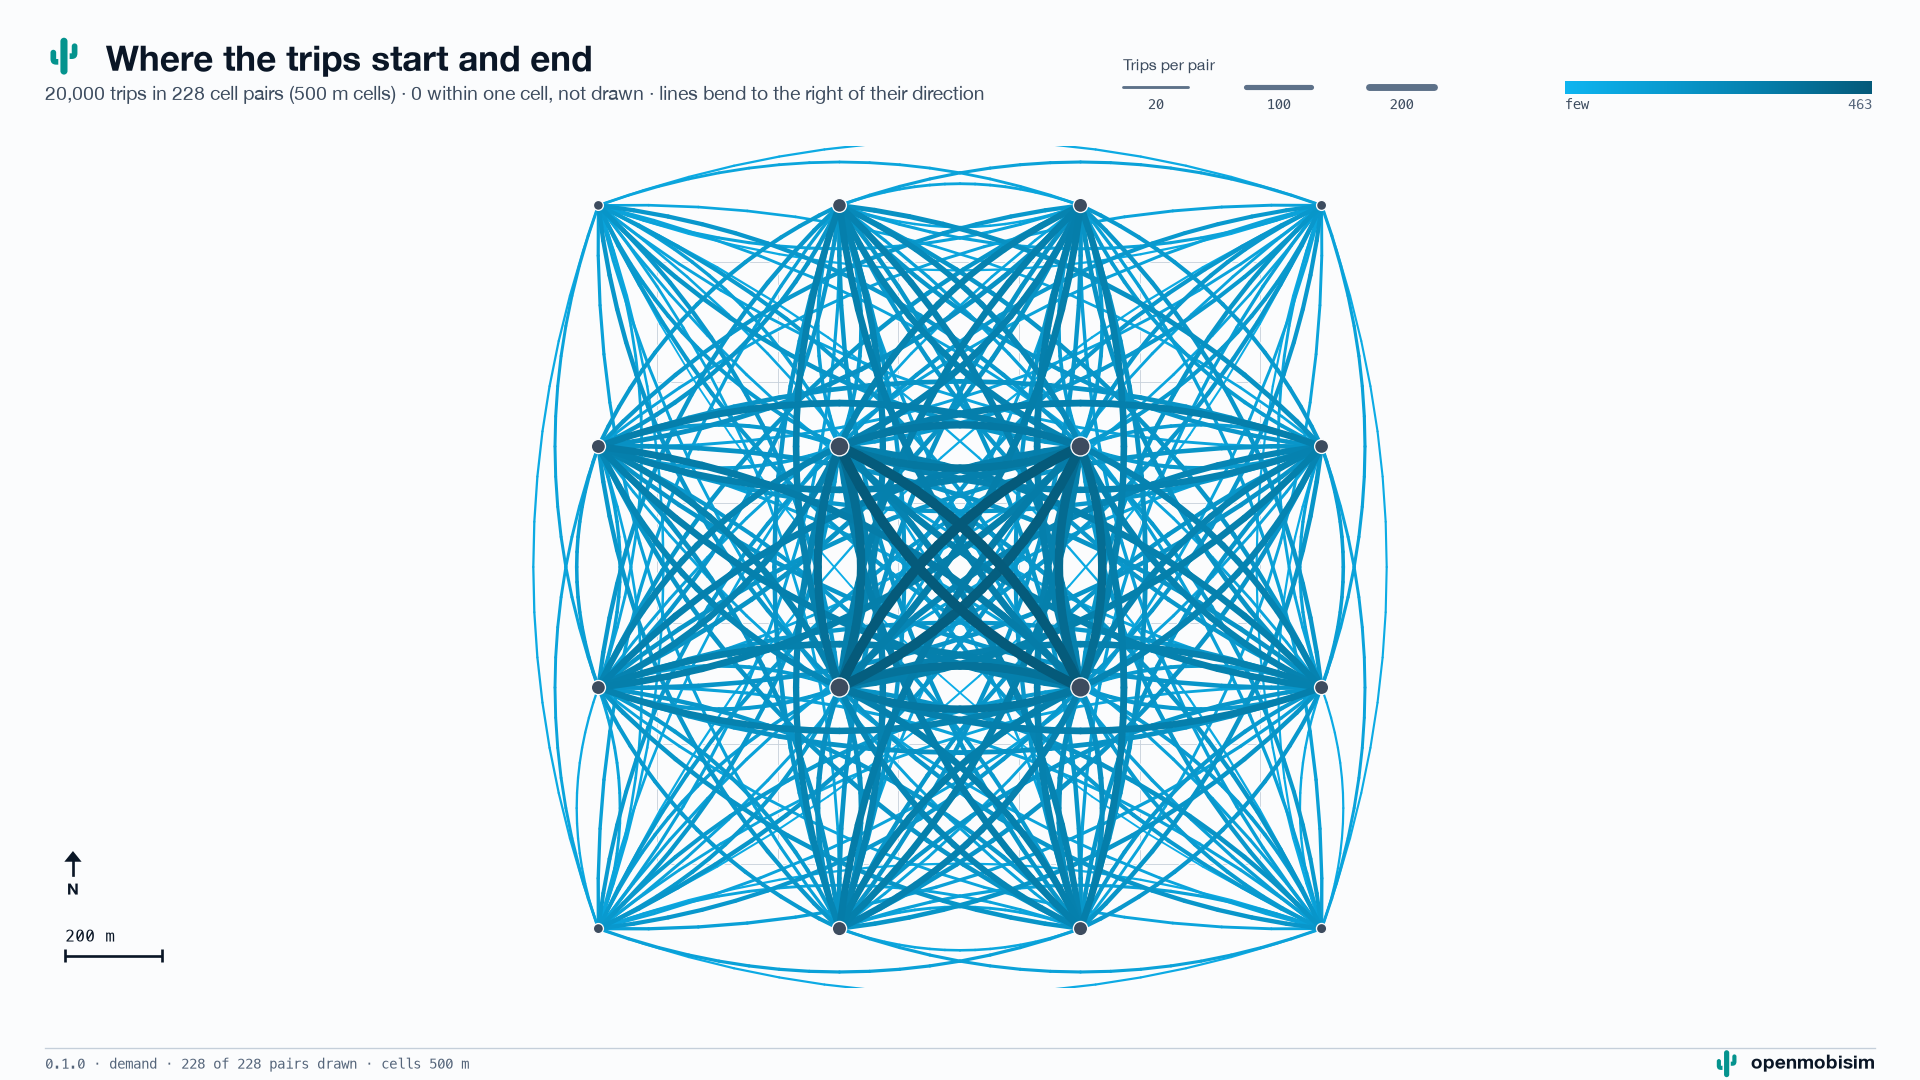

In [11]:
viz.map_demand(trips, network=net, title="Where the trips start and end")

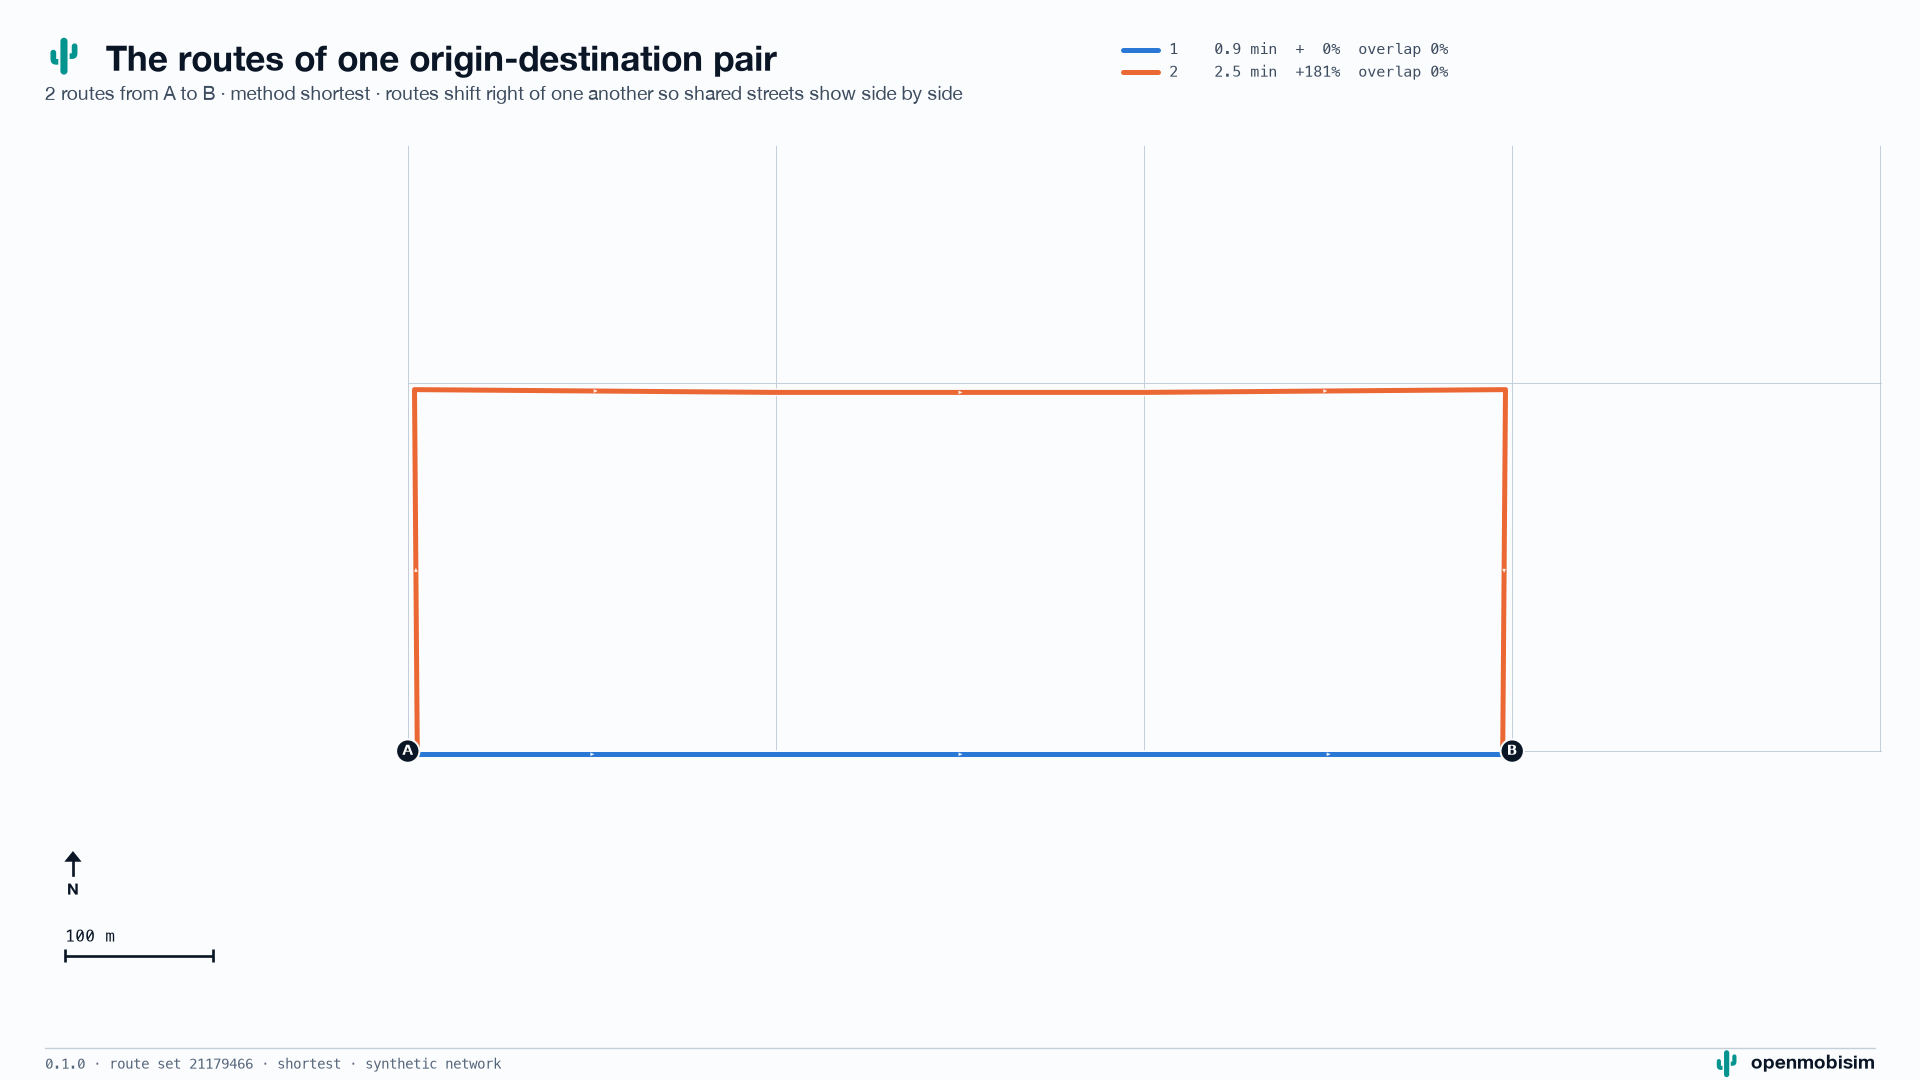

In [12]:
viz.map_route(run.route_sets(), net, 0, title="The routes of one origin-destination pair")

**Interactive and summary pages.** `map_interactive` writes one self-contained HTML file to open in a browser: pan and
zoom, step through the time bins, click a link for its numbers, show a pair's routes. `summary` writes a one-page
report of a run: headline numbers, the flow map, the modes, the convergence and where the time went.

In [13]:
page = viz.map_interactive(run, "runs/results/interactive.html", title="A 6 x 6 grid")
report = viz.summary(run, note="A synthetic hour on a 6 x 6 grid")
print(page, report, sep="\n")

**Interactive map:** [runs/results/interactive.html](runs/results/interactive.html) — file:///private/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/tmpqg8o53bk/runs/results/interactive.html

**Summary page:** [runs/results/summary.html](runs/results/summary.html) — file:///private/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/tmpqg8o53bk/runs/results/summary.html

runs/results/interactive.html
runs/results/summary.html


**Saving.** `path=` saves a figure as it is drawn, at its size and `dpi`:

In [14]:
viz.map_link(run, title="Flows on a 6 x 6 grid", size_cm=(17.0, 10.0), dpi=300, path="runs/results/flows.pdf")
print(os.path.getsize("runs/results/flows.pdf"), "bytes")

54503 bytes


**Next:** [06 · Parameters and experiments](06_parameters_and_experiments.ipynb): every default by name, seeds and replications, samples, sweeps; a city's mode shares moved. The whole series: [00 · overview](00_getting_started.ipynb). The documentation: [openmobisim.github.io](https://openmobisim.github.io). Something wrong or unclear? [Report it](https://github.com/bahmanmdd/openmobisim/issues).